# Multinomial and one-vs-rest logistic regression

Fit the two strategies with default L-BFGS settings on 1,000 samples
from three overlapping classes. Multinomial logistic regression fits
all classes jointly. One-vs-rest fits three independent binary models.

The [scikit-learn gallery example](https://scikit-learn.org/dev/auto_examples/linear_model/plot_logistic_multinomial.html)
supplies the dataset recipe at revision `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.
Dataset recipe adapted from the scikit-learn developers under the
[BSD 3-Clause License](../../families/linear_model/LICENSES/scikit-learn.txt).

In [1]:
import runpy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("linear_model/plot_logistic_multinomial")

logistic_tests = ROOT / "families/linear_model/algorithms/logistic/tests/parity.py"
logistic_oracle = runpy.run_path(str(logistic_tests))
LogisticRegression = logistic_oracle["oracle"]()

from parity_io import load_pinned, pinned_code, verify_reference

multiclass_source = "sklearn/multiclass.py"
verify_reference([multiclass_source, "examples/linear_model/plot_logistic_multinomial.py"])
OneVsRestClassifier = load_pinned(multiclass_source).OneVsRestClassifier
pinned_code(OneVsRestClassifier.fit, multiclass_source)
pinned_code(OneVsRestClassifier.predict, multiclass_source)

scikit-learn source SHA256 {'sklearn/linear_model/_linear_loss.py': 'db6fd7e23b4619a76a46b8225876646328930db42d42e6af76223f72674afa3e', 'sklearn/linear_model/_logistic.py': '30863a8c7be82a63e2994405cf3fb29a4ab069eccb74ea6720582b4d8dec0b99', 'sklearn/linear_model/_glm/_newton_solver.py': 'f9c7caf323700d69d52ff709ea5e82d5c5fcfaa433f216cadaffce81621f6eae', 'sklearn/utils/optimize.py': '5f8d9a9ca0fb8e15624f4669f9ed5a2afe74c4e119cc4cb392a16df4eaeee575', 'sklearn/svm/_base.py': 'be4d5a830d357be28e2a85d6c80c208d8aa8536858a62e17cad50abf0f7fe62f', 'sklearn/svm/_liblinear.pyx': '91f175ac10f6d6b711fb09f975f2d5aa1cd9416bcc1cc668ae5be6eb250a7480', 'sklearn/svm/src/liblinear/linear.cpp': 'c5329418a6de7470ead7a858fd57b6e686ada53d102235cb3e1457fd0137a9d4', 'sklearn/svm/src/liblinear/linear.h': 'c3bd0dfc7bbc35a4ec9b16137df5df3938296cad676dca73540893d4e3ac88db', 'sklearn/svm/src/liblinear/tron.cpp': '4b942fe335f1475d89048c2b3492d14c5884975b9beeae3604bba5605076400d', 'sklearn/svm/src/liblinear/tron.h': '

## scikit-learn reference

Both models see the same training data. A shared grid lets us compare
predictions and class scores between the sample points.

In [2]:
X, y = make_blobs(
    n_samples=1_000, centers=[[-5, 0], [0, 1.5], [5, -1]], random_state=40
)
X = X @ np.array([[0.4, 0.2], [-0.4, 1.2]])
x0, x1 = (np.linspace(column.min(), column.max(), 120) for column in X.T)
xx, yy = np.meshgrid(x0, x1)
grid = np.column_stack((xx.ravel(), yy.ravel()))

models = {
    "multinomial": LogisticRegression().fit(X, y),
    "ovr": OneVsRestClassifier(LogisticRegression()).fit(X, y),
}
nb.share(X=X, y=y, grid=grid)

## Moxie

The Mojo program uses the public estimators for fitting, predictions,
probabilities, scores and class decisions. Python shares the data,
compares results and renders figures.

In [3]:
%%mojo logistic_multinomial
from moxie.linear_model import LogisticRegression
from moxie.multiclass import OneVsRestClassifier
from moxie_nb_io import load, save, save_floats

def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var grid = load("grid")

    var multinomial = LogisticRegression()
    _ = multinomial.fit(X, y)
    save("multinomial_classes", multinomial.classes_)
    save("multinomial_train_pred", multinomial.predict(X))
    save("multinomial_grid_pred", multinomial.predict(grid))
    save("multinomial_decision", multinomial.decision_function(grid))
    save("multinomial_proba", multinomial.predict_proba(grid))
    save_floats("multinomial_accuracy", [multinomial.score(X, y)])

    var ovr = OneVsRestClassifier(LogisticRegression())
    _ = ovr.fit(X, y)
    save("ovr_classes", ovr.classes_)
    save("ovr_train_pred", ovr.predict(X))
    save("ovr_grid_pred", ovr.predict(grid))
    save("ovr_decision", ovr.decision_function(grid))
    save("ovr_proba", ovr.predict_proba(grid))
    save_floats("ovr_accuracy", [ovr.score(X, y)])

## Decision regions and probability contours

Shading shows each model's predicted class. The dashed contours show
where each multinomial softmax probability reaches 0.5, or where each
one-vs-rest binary model reaches 0.5 before its probabilities are
normalized across classes. The multinomial contours can curve because
each softmax probability depends on every class score. The titles report
training accuracy.

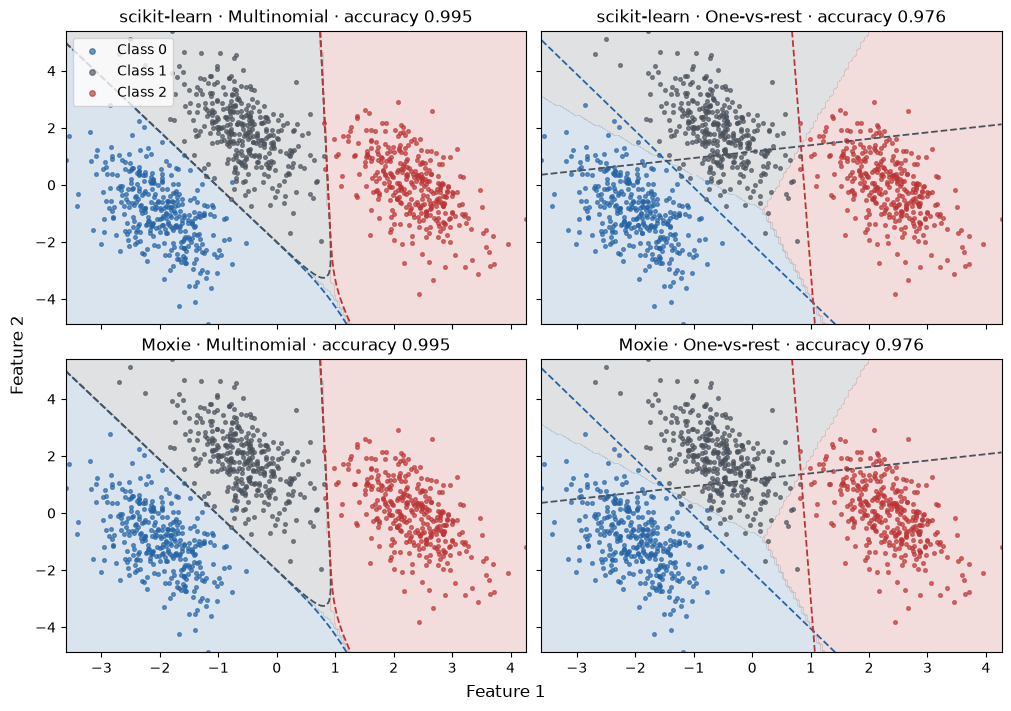

In [4]:
native = nb.results["logistic_multinomial"]
expected = {}
for name, model in models.items():
    expected.update({
        f"{name}_classes": model.classes_,
        f"{name}_train_pred": model.predict(X),
        f"{name}_grid_pred": model.predict(grid),
        f"{name}_decision": model.decision_function(grid),
        f"{name}_proba": model.predict_proba(grid),
        f"{name}_accuracy": [model.score(X, y)],
    })

colors = ["#2463a5", "#49515a", "#bd3434"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True,
                         layout="constrained")
engines = (("scikit-learn", expected), ("Moxie", native))
strategies = (("multinomial", "Multinomial"), ("ovr", "One-vs-rest"))
for row_axes, (engine, results) in zip(axes, engines):
    for ax, (name, title) in zip(row_axes, strategies):
        prediction = results[f"{name}_grid_pred"].reshape(xx.shape)
        ax.contourf(xx, yy, prediction, levels=[-0.5, 0.5, 1.5, 2.5],
                    colors=colors, alpha=0.17)
        for column, color in enumerate(colors):
            mask = y == column
            ax.scatter(X[mask, 0], X[mask, 1], s=7, color=color, alpha=0.65,
                       label=f"Class {column}")
            if name == "multinomial":
                values, threshold = results[f"{name}_proba"][:, column], 0.5
            else:
                values, threshold = results[f"{name}_decision"][:, column], 0.0
            ax.contour(xx, yy, values.reshape(xx.shape), levels=[threshold],
                       colors=[color], linestyles="--", linewidths=1.3)
        accuracy = results[f"{name}_accuracy"][0]
        ax.set_title(f"{engine} · {title} · accuracy {accuracy:.3f}")
axes[0, 0].legend(loc="upper left", markerscale=1.5)
fig.supxlabel("Feature 1")
fig.supylabel("Feature 2")
plt.show()

In [5]:
for key, values in expected.items():
    assert np.asarray(values).dtype == native[key].dtype, key

for name in models:
    for field in ("classes", "train_pred", "grid_pred", "accuracy"):
        key = f"{name}_{field}"
        nb.compare(key, expected[key], native[key], exact=True)
    for field, tolerance in (("decision", 5e-6), ("proba", 2e-6)):
        key = f"{name}_{field}"
        nb.compare(key, expected[key], native[key], rtol=0, atol=tolerance,
                   reason="Float64 L-BFGS accumulation and line search can differ.")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
multinomial_classes,PASS,"(3,)","(3,)",,,exact,0 mismatches,
multinomial_train_pred,PASS,"(1000,)","(1000,)",,,exact,0 mismatches,
multinomial_grid_pred,PASS,"(14400,)","(14400,)",,,exact,0 mismatches,
multinomial_accuracy,PASS,"(1,)","(1,)",,,exact,0 mismatches,
multinomial_decision,PASS,"(14400, 3)","(14400, 3)",8.57e-12,1.95e-08,"rtol=0, atol=5e-06",,Float64 L-BFGS accumulation and line search can differ.
multinomial_proba,PASS,"(14400, 3)","(14400, 3)",1.07e-13,6.11e-12,"rtol=0, atol=2e-06",,Float64 L-BFGS accumulation and line search can differ.
ovr_classes,PASS,"(3,)","(3,)",,,exact,0 mismatches,
ovr_train_pred,PASS,"(1000,)","(1000,)",,,exact,0 mismatches,
ovr_grid_pred,PASS,"(14400,)","(14400,)",,,exact,0 mismatches,
ovr_accuracy,PASS,"(1,)","(1,)",,,exact,0 mismatches,
